# T-RAG · Live demo (GPU)

## About this notebook

**What it does :** This is the live demo used in our presentation. It loads the final system and provides one function, `ask(question, as_of)`. It answers any question about the ten companies or the Fed **as of any date**, showing standard RAG (B2) next to the full T-RAG (B6). For each question it shows every step:
* the router's plan: question type and time window;
* the documents each system read, with their dates. Anything published after the as-of date is marked in red;
* the exact numbers from the tools: sentiment timeline, events with stock reactions, prices and the knowledge graph;
* both final answers, with reasoning steps and cited documents.

All the code is copied from Notebook 5, so it is the same system that produced our results.

Four prepared scenes show the main ideas:
1. AMD's latest revenue, asked on two dates before and after a new quarter was published. The answer must change.
2. Nvidia's reaction to the August 2022 US rule on AI-chip exports to China, and which other companies the rule hit (the knowledge graph).
3. Tesla news in August 2021, before our news coverage starts. T-RAG answers "insufficient data".
4. Tesla's sentiment over two years, with a timeline chart.

The last cell is for your own question.

**Needs :** Notebook 4's output. GPU T4 ×2, internet on. About 8–10 minutes to load, then 30–60 seconds per question.

In [1]:
# ============================ CONFIG ============================
from pathlib import Path
import glob

def find_local_qwen():
    """A Qwen2.5-7B-Instruct attached from Kaggle Models, if any (saves the 15 GB download)."""
    for cfg in sorted(glob.glob("/kaggle/input/**/config.json", recursive=True)):
        p = cfg.lower()
        if "qwen" in p and "7b" in p and "instruct" in p and Path(cfg).with_name("tokenizer_config.json").exists():
            return str(Path(cfg).parent)
    return None

LLM_MODEL = find_local_qwen() or "Qwen/Qwen2.5-7B-Instruct"
LOAD_4BIT = False                          # switched on automatically if only one GPU is visible
RUN_NAME, VERSIONS, LLM_BATCH = "demo", ["B2", "B6"], 2
RERANK_MODEL = "BAAI/bge-reranker-base"
END = "2023-12-31"                         # default as-of date
TOP_K, N_EACH, N_RERANK = 8, 100, 50
HALF_LIFE_DAYS, LAMBDA, HALF_LIFE_EVENT, LATEST_DAYS = 30, 0.5, 5, 120
MIN_N = {"news": 20, "social": 10}
QUARTER_MIN_N = {"news": 60, "social": 30}
POS_T, NEG_T, MIX_T = 0.25, -0.25, 0.08
MAX_NEW_TOKENS, MAX_NEW_TOKENS_STEPS = 160, 320
SEED = 42
print("LLM:", LLM_MODEL)

LLM: Qwen/Qwen2.5-7B-Instruct


In [2]:
!pip install -q sentence-transformers accelerate bitsandbytes

In [3]:
import re, json, time, glob, pickle, warnings, traceback
from collections import defaultdict
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import binomtest
warnings.filterwarnings("ignore")
pd.set_option("display.width", 180, "display.max_columns", 30, "display.max_colwidth", 120)
N_GPU = torch.cuda.device_count()
DEV0 = "cuda:0" if N_GPU else "cpu"
print("torch", torch.__version__, "| GPUs:", N_GPU, [torch.cuda.get_device_name(i) for i in range(N_GPU)])
SUMMARY, T0 = {"run": RUN_NAME, "llm": LLM_MODEL, "versions": VERSIONS}, time.time()
def hours(): return (time.time() - T0) / 3600

TICKERS = ["TSLA", "AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "NFLX", "AMD", "INTC"]
COMPANY = {"TSLA": "Tesla", "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "Nvidia", "AMZN": "Amazon",
           "META": "Meta", "GOOGL": "Alphabet", "NFLX": "Netflix", "AMD": "AMD", "INTC": "Intel", "ALL": "the market"}

torch 2.11.0+cu130 | GPUs: 2 ['Tesla T4', 'Tesla T4']


## Load the index (Notebook 4's output)

In [4]:
def find_input(name, folder="trag_index_v2"):
    hits = sorted(glob.glob(f"/kaggle/input/**/{folder}/{name}", recursive=True)) + sorted(glob.glob(f"{folder}/{name}"))
    return hits[0] if hits else None
def need(name):
    p = find_input(name)
    if p is None: raise FileNotFoundError(f"trag_index_v2/{name} not found — attach Notebook 4's output.")
    return p

chunks = pd.read_parquet(need("chunks_v2.parquet"))
E = np.load(need("embeddings_v2.npy")).astype(np.float32)
assert len(chunks) == len(E), "chunks and embeddings are out of sync"
events = pd.read_parquet(need("events_v2.parquet"))
prices = pd.read_parquet(need("prices.parquet"))
TRADING_DAYS = pd.DatetimeIndex(pd.read_parquet(need("trading_days.parquet"))["date"])
coverage = pd.read_csv(need("coverage_v2.csv"))
manifest = json.loads(Path(need("manifest_v2.json")).read_text())
release_facts = pd.read_parquet(find_input("release_facts.parquet")) if find_input("release_facts.parquet") else pd.DataFrame()
releases = pd.read_parquet(find_input("releases.parquet")) if find_input("releases.parquet") else pd.DataFrame()
G = pickle.load(open(need("graph/graph.pkl"), "rb"))
jp = sorted(glob.glob("/kaggle/input/**/trag_judge/llm_labels.parquet", recursive=True)) + sorted(glob.glob("trag_judge/llm_labels.parquet"))
judge = pd.read_parquet(jp[0]) if jp else None
EMBED_MODEL, QUERY_PREFIX = manifest["embedder"], manifest["query_prefix"]
events["day0"] = pd.to_datetime(events.day0); events["event_date"] = pd.to_datetime(events.event_date)
print(f"{len(chunks):,} documents", chunks.source.value_counts().to_dict())
print(f"events {len(events):,} | revenue quarters {len(release_facts)} | graph {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges"
      f" | judge labels: {'yes' if judge is not None else 'no'}")

chunks["day0"] = pd.to_datetime(chunks.day0)
TICK = chunks.ticker.astype(str).values
SRC = chunks.source.astype(str).values
AV = pd.to_datetime(chunks.available_at, utc=True).values.astype("datetime64[ns]").astype(np.int64)   # UTC ns
DAY0 = chunks.day0.values.astype("datetime64[ns]")
POS = (chunks.label == "positive").values
NEG = (chunks.label == "negative").values
DOC_ID = chunks.doc_id.astype(str).values
DOC_IX = {d: i for i, d in enumerate(DOC_ID)}
PER_M = chunks.day0.dt.to_period("M")
PER_Q = chunks.day0.dt.to_period("Q")
DAY_NS = 86_400 * 10**9
coverage["coverage_start"] = pd.to_datetime(coverage.coverage_start)
coverage["coverage_end"] = pd.to_datetime(coverage.coverage_end)
COV = {(r.ticker, r.source): (r.coverage_start, r.coverage_end) for r in coverage.itertuples()}

J_HAS = J_POS = J_NEG = None
if judge is not None:
    jl = pd.DataFrame({"doc_id": DOC_ID}).merge(judge[["doc_id", "judge_label"]].drop_duplicates("doc_id"), on="doc_id", how="left")
    J_HAS = jl.judge_label.notna().values
    J_POS = (jl.judge_label == "positive").values
    J_NEG = (jl.judge_label == "negative").values
    print(f"LLM-judge labels available for {J_HAS.mean():.1%} of documents "
          f"(news {J_HAS[SRC == 'news'].mean():.1%}, social {J_HAS[SRC == 'social'].mean() if (SRC == 'social').any() else 0:.1%})")

prices["date"] = pd.to_datetime(prices.date)
RET = prices.pivot_table(index="date", columns="ticker", values="ret").sort_index()
ARW = prices.pivot_table(index="date", columns="ticker", values="ar").sort_index()
ZW = prices.pivot_table(index="date", columns="ticker", values="z").sort_index()

def ts(x): return pd.Timestamp(str(x)) if isinstance(x, np.str_) else pd.Timestamp(x)
def day_start(d): return ts(d).tz_localize("America/New_York").value
def cutoff(d): return (ts(d).tz_localize("America/New_York") + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)).value

def time_mask(t, start=None, end=None, as_of=None, srcs=("news",)):
    m = (TICK == t) & np.isin(SRC, list(srcs))
    if start is not None: m &= AV >= day_start(start)
    if end is not None:   m &= AV <= cutoff(end)
    if as_of is not None: m &= AV <= cutoff(as_of)
    return m

def lab_arrays(lab):
    if lab == "finbert": return POS, NEG, None
    if J_HAS is None: raise ValueError("no judge labels loaded")
    return J_POS, J_NEG, J_HAS

def tone_of(m, lab="finbert"):
    P, N, H = lab_arrays(lab)
    if H is not None: m = m & H
    pos, neg = int(P[m].sum()), int(N[m].sum())
    return (pos - neg) / (pos + neg + 1), int(m.sum())

def tone_label(x):
    if x >= POS_T: return "positive"
    if x <= NEG_T: return "negative"
    if abs(x) <= MIX_T: return "mixed"
    return None

_tables = {}
def period_table(t, src, freq="M", lab="finbert"):
    key = (t, src, freq, lab)
    if key not in _tables:
        P, N, H = lab_arrays(lab)
        m = (TICK == t) & (SRC == src)
        if H is not None: m &= H
        per = (PER_M if freq == "M" else PER_Q)[m].values
        g = pd.DataFrame({"per": per, "pos": P[m], "neg": N[m]}).groupby("per").agg(
            n=("pos", "size"), pos=("pos", "sum"), neg=("neg", "sum")).reset_index()
        g["tone"] = (g.pos - g.neg) / (g.pos + g.neg + 1)
        g["start"] = g.per.dt.start_time; g["end"] = g.per.dt.end_time.dt.normalize()
        cs, ce = COV.get((t, src), (pd.Timestamp("2100-01-01"), pd.Timestamp("1900-01-01")))
        need = (MIN_N if freq == "M" else QUARTER_MIN_N)[src]
        g["ok"] = (g.n >= need) & (g.start >= cs) & (g.start <= ce) & (g.end <= ts(END))
        _tables[key] = g.sort_values("per").reset_index(drop=True)
    return _tables[key]

def excess_return(t, s, e, as_of=None):
    e2 = min(ts(e), ts(as_of)) if as_of is not None else ts(e)
    r = RET.loc[(RET.index >= ts(s)) & (RET.index <= e2)]
    if len(r) < 2 or t not in r or "QQQ" not in r: return None
    st = float((1 + r[t].fillna(0)).prod() - 1); mk = float((1 + r["QQQ"].fillna(0)).prod() - 1)
    return st, mk, st - mk, len(r)

def truth_from_spec(spec, lab="finbert"):
    """The answer key of a question, recomputed from a given set of labels. None = no clear answer."""
    if isinstance(spec, str): spec = json.loads(spec)
    k = spec["kind"]
    if k == "fixed": return spec["truth"]
    t, src = spec["t"], spec.get("src", "news")
    if k == "month_label":
        g = period_table(t, src, "M", lab); r = g[(g.per.astype(str) == spec["per"]) & g.ok]
        return tone_label(r.tone.iloc[0]) if len(r) else None
    if k == "window_label":
        x, n = tone_of(time_mask(t, spec["start"], spec["end"], srcs=[src]), lab)
        return tone_label(x) if n >= spec["min_n"] else None
    if k == "trend":
        g = period_table(t, src, "M", lab)
        ok = g[g.ok & (g.start >= ts(spec["start"])) & (g.end <= ts(spec["end"]))]
        if len(ok) < 4: return None
        d = ok.tone.iloc[-2:].mean() - ok.tone.iloc[:2].mean()
        return None if abs(d) < 0.3 else ("improved" if d > 0 else "worsened")
    if k == "extreme":
        g = period_table(t, src, "M", lab); m = g[g.ok & (g.per.dt.year == spec["year"])]
        if len(m) < 9: return None
        srt = m.sort_values("tone", ascending=(spec["which"] == "most negative"))
        return None if abs(srt.tone.iloc[0] - srt.tone.iloc[1]) < 0.05 else srt.per.iloc[0].strftime("%Y-%m")
    if k == "quarter_compare":
        g = period_table(t, src, "Q", lab)
        a = g[(g.per.astype(str) == spec["pa"]) & g.ok]; b = g[(g.per.astype(str) == spec["pb"]) & g.ok]
        if not len(a) or not len(b) or abs(a.tone.iloc[0] - b.tone.iloc[0]) < 0.25: return None
        return spec["la"] if a.tone.iloc[0] > b.tone.iloc[0] else spec["lb"]
    if k == "before_after":
        d = ts(spec["d"])
        xb, nb = tone_of(time_mask(t, d - pd.Timedelta(days=28), d - pd.Timedelta(days=1), srcs=[src]), lab)
        xa, na = tone_of(time_mask(t, d, d + pd.Timedelta(days=27), srcs=[src]), lab)
        if min(nb, na) < 15 or abs(xa - xb) < 0.2: return None
        return "after" if xa > xb else "before"
    if k == "m1":
        g = period_table(t, src, "M", lab); m = g[g.ok & (g.per.dt.year == spec["year"])]
        if len(m) < 9: return None
        srt = m.sort_values("tone")
        if abs(srt.tone.iloc[0] - srt.tone.iloc[1]) < 0.05: return None
        r = srt.iloc[0]; x = excess_return(t, r.start, r.end)
        if x is None or abs(x[2]) < 0.03: return None
        return "outperformed" if x[2] > 0 else "underperformed"
    raise ValueError(k)

TEXT = chunks.text_for_scoring.astype(str).values
CHUNK_TEXT = chunks.chunk_text.astype(str).values
SCORE, LABEL = chunks.score.values, chunks.label.values
DAY0_STR = chunks.day0.dt.strftime("%Y-%m-%d").values
SRC_NAME = {"news": "news", "social": "tweet", "filing": "SEC filing", "fed": "Federal Reserve"}
print(coverage.to_string(index=False))

# --- helpers from Notebook 5, Step 2

END_TS = ts(END)
D = pd.Timedelta
EVT = events[(events.ticker_scope != "ALL") & events.ticker.isin(TICKERS)].copy()
def fmt(d): return pd.Timestamp(d).strftime("%Y-%m-%d")
def car_known(day0, as_of):
    i = TRADING_DAYS.searchsorted(ts(day0)); j = TRADING_DAYS.searchsorted(ts(as_of), side="right") - 1
    return i + 3 <= j

def sources_for(question):
    """Which document sources a question is about, read from its wording (same rule for every version)."""
    ql = question.lower()
    if "social media" in ql or "twitter" in ql: return ["social"]
    if "federal reserve" in ql: return ["fed"]
    if "revenue" in ql: return ["filing", "news"]
    if re.search(r"\bstock\b|earnings|react", ql): return ["news", "filing"]
    return ["news"]

108,054 documents {'social': 57516, 'news': 49993, 'filing': 521, 'fed': 24}
events 740 | revenue quarters 88 | graph 1,598 nodes, 4,269 edges | judge labels: no
ticker source coverage_start coverage_end  n_docs  months_covered
  AAPL filing     2021-01-28   2023-11-03      48              12
  AAPL   news     2022-06-01   2023-12-31    8002              19
  AAPL social     2021-10-01   2022-09-30    4930              12
   AMD filing     2021-01-27   2023-11-01      52              13
   AMD   news     2021-01-01   2023-12-31    4465              35
   AMD social     2021-10-01   2022-09-30    2182              12
  AMZN filing     2021-02-03   2023-10-27      48              12
  AMZN   news     2023-03-01   2023-12-31    4293              10
  AMZN social     2021-10-01   2022-09-30    4005              12
 GOOGL filing     2021-02-03   2023-10-25      52              12
 GOOGL   news     2021-01-01   2023-12-31    5077              36
 GOOGL social     2021-10-01   2022-09-30    1

## Search: keyword + semantic, reranker (as in Notebook 5)

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sentence_transformers import SentenceTransformer, CrossEncoder

cv = CountVectorizer(lowercase=True, stop_words="english", min_df=2, dtype=np.float32)
Xc = cv.fit_transform(CHUNK_TEXT)
dl = np.asarray(Xc.sum(axis=1)).ravel(); avgdl = dl.mean(); N_DOCS = Xc.shape[0]
dfreq = np.asarray((Xc > 0).sum(axis=0)).ravel()
idf = np.log(1 + (N_DOCS - dfreq + 0.5) / (dfreq + 0.5))
Xo = Xc.tocoo(); k1, b = 1.5, 0.75
W = sparse.csc_matrix((Xo.data * (k1 + 1) / (Xo.data + k1 * (1 - b + b * dl[Xo.row] / avgdl)) * idf[Xo.col],
                       (Xo.row, Xo.col)), shape=Xc.shape)
del Xc, Xo
def bm25(query):
    cols = cv.transform([query]).indices
    return np.asarray(W[:, cols].sum(axis=1)).ravel() if len(cols) else np.zeros(N_DOCS, np.float32)
print(f"BM25 index: {N_DOCS:,} docs × {W.shape[1]:,} terms")

emb = SentenceTransformer(EMBED_MODEL, device=DEV0)
ce = CrossEncoder(RERANK_MODEL, device=DEV0, max_length=512)
if N_GPU:
    emb = emb.half()
    try: ce.model.half()
    except Exception: pass

_qcache = {}
def query_scores(query):
    if query not in _qcache:
        qv = emb.encode([QUERY_PREFIX + query], normalize_embeddings=True)[0].astype(np.float32)
        _qcache[query] = (bm25(query), E @ qv)
    return _qcache[query]

def fused(query, mask, n_each=N_EACH):
    idx = np.flatnonzero(mask)
    if len(idx) == 0: return idx
    bm, dn = query_scores(query)
    n = min(n_each, len(idx)); rrf = {}
    for ranked in (idx[np.argsort(-bm[idx])[:n]], idx[np.argsort(-dn[idx])[:n]]):
        for r, c in enumerate(ranked):
            rrf[c] = rrf.get(c, 0.0) + 1.0 / (60 + r + 1)
    return np.array(sorted(rrf, key=rrf.get, reverse=True), dtype=np.int64)

_rcache = {}
def rerank_scores(query, idx):
    todo = [i for i in idx if (query, i) not in _rcache]
    if todo:
        sc = ce.predict([(query, CHUNK_TEXT[i]) for i in todo], batch_size=64, show_progress_bar=False)
        for i, s in zip(todo, np.asarray(sc, np.float32)): _rcache[(query, i)] = float(s)
    return np.array([_rcache[(query, i)] for i in idx], np.float32)

def top_k(query, mask, anchor_ns=None, half_life=HALF_LIFE_DAYS, lam=LAMBDA, k=TOP_K):
    cand = fused(query, mask)[:N_RERANK]
    if len(cand) == 0: return []
    rel = rerank_scores(query, cand); rel = (rel - rel.min()) / (rel.max() - rel.min() + 1e-9)
    score = rel
    if anchor_ns is not None:
        score = (1 - lam) * rel + lam * 0.5 ** (np.abs(AV[cand] - anchor_ns) / (half_life * DAY_NS))
    return [int(i) for i in cand[np.argsort(-score)[:k]]]

def spread(query, mask, segs, per_seg=1):
    pool = fused(query, mask, n_each=300); picks = []
    for s, e in segs:
        sel = pool[(AV[pool] >= s) & (AV[pool] <= e)]
        picks += [int(i) for i in sel[:per_seg]]
    return sorted(set(picks), key=lambda i: AV[i])

def segments(start, end, k):
    edges = np.linspace(day_start(start), cutoff(end), k + 1).astype(np.int64)
    return list(zip(edges[:-1], edges[1:]))

STOP = set(ENGLISH_STOP_WORDS)
SNIP = {"news": 350, "social": 280, "filing": 750, "fed": 750}
def snippet(i, query):
    txt, n = TEXT[i], SNIP.get(SRC[i], 350)
    if len(txt) <= n or SRC[i] in ("news", "social"): return txt[:n]
    terms = {w for w in re.findall(r"[a-z]+", query.lower()) if w not in STOP and len(w) > 2}
    sents = re.split(r"(?<=[.!?])\s+", txt); best, bs = 0, -1.0
    for k in range(len(sents)):
        win = " ".join(sents[k:k + 4])[:n].lower()
        sc = sum(win.count(w) for w in terms) + 0.5 * len(re.findall(r"\d[\d,.]*\s*(?:billion|million|percent|%)", win))
        if sc > bs: best, bs = k, sc
    return " ".join(sents[best:best + 4])[:n]
print("Retrieval ready.")

BM25 index: 108,054 docs × 38,170 terms


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

... (15 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Retrieval ready.


## Load the language model (Qwen2.5-7B-Instruct)

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

def resolve_model(name):
    """HF id, local folder, or 'kaggle:<pattern>' for a model attached from Kaggle Models."""
    if name.startswith("kaggle:"):
        pat = name.split(":", 1)[1].strip("/")
        hits = sorted(glob.glob(f"/kaggle/input/{pat}/**/config.json", recursive=True))
        hits = [h for h in hits if Path(h).parent.joinpath("tokenizer_config.json").exists()] or hits
        if not hits:
            raise FileNotFoundError(f"No model matching /kaggle/input/{pat} — attach it via Add Input → Models.")
        return str(Path(hits[0]).parent)
    return name

class LLM:
    def __init__(self, name, load_4bit=False, max_memory=None):
        path = resolve_model(name)
        self.tok = AutoTokenizer.from_pretrained(path)
        self.tok.padding_side = "left"
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        kw = {"device_map": "auto"}
        if max_memory: kw["max_memory"] = max_memory
        if load_4bit:
            from transformers import BitsAndBytesConfig
            kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                           bnb_4bit_compute_dtype=torch.float16)
        try:
            self.model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float16, **kw)
        except TypeError:
            self.model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.float16, **kw)
        self.model.eval()
        gc = self.model.generation_config
        gc.temperature = gc.top_p = gc.top_k = None; gc.do_sample = False

    def prompts(self, pairs):
        return [self.tok.apply_chat_template([{"role": "system", "content": s}, {"role": "user", "content": u}],
                                             tokenize=False, add_generation_prompt=True) for s, u in pairs]

    def chat(self, pairs, max_new_tokens=160, batch_size=12, name=""):
        prompts = self.prompts(pairs)
        order = np.argsort([-len(p) for p in prompts])          # longest first: an OOM shows up immediately
        outs, i, bs, t0 = [None] * len(prompts), 0, batch_size, time.time()
        while i < len(order):
            idx = order[i:i + bs]
            try:
                enc = self.tok([prompts[j] for j in idx], return_tensors="pt", padding=True,
                               add_special_tokens=False).to(self.model.device)
                with torch.inference_mode():
                    gen = self.model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                              pad_token_id=self.tok.pad_token_id)
                texts = self.tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
                for j, txt in zip(idx, texts): outs[j] = txt
                i += len(idx)
                if (i // max(bs, 1)) % 10 == 0 or i >= len(order):
                    print(f"  {name}: {i}/{len(order)} | {time.time()-t0:5.0f}s")
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache(); bs = max(1, bs // 2); print(f"  OOM → batch size {bs}")
        return outs

def parse_json(txt):
    txt = txt or ""
    s, e = txt.find("{"), txt.rfind("}")
    if s >= 0 and e > s:
        frag = txt[s:e + 1]
        for cand in (frag, frag.replace("'", '"'), re.sub(r",\s*([}\]])", r"\1", frag)):
            try:
                out = json.loads(cand)
                if isinstance(out, dict): return out
            except Exception:
                pass
    m = re.search(r'"answer"\s*:\s*"([^"]*)"', txt)
    return {"answer": m.group(1) if m else txt.strip()[:120],
            "doc_ids": re.findall(r"(?:news_\d{7}|tw_[0-9a-f]{12}|fil_[A-Z]+_\d+_\d|fed_\d{8})", txt), "_unparsed": True}

t_load = time.time()
if N_GPU < 2 and not LOAD_4BIT:
    print("⚠️ Only one GPU visible: loading in 4-bit to fit."); LOAD_4BIT = True
llm = LLM(LLM_MODEL, load_4bit=LOAD_4BIT, max_memory={0: "6GiB" if LOAD_4BIT else "11GiB", 1: "14GiB"} if N_GPU >= 2 else None)
print(f"Loaded {LLM_MODEL} ({'4-bit' if LOAD_4BIT else 'fp16'}) in {time.time()-t_load:.0f}s")
print("Sanity check:", llm.chat([("You are helpful.", "Reply with exactly: OK, ready.")], max_new_tokens=10, name="check"))

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-7B-Instruct (fp16) in 107s
  check: 1/1 |     2s
Sanity check: ['OK, ready.']


## Router, time rules, knowledge graph and tools (as in Notebook 5)

In [7]:
ROUTER_SYSTEM = "You turn a question about companies and markets into a retrieval plan. Reply with one JSON object only."
ROUTER_RULES = """Question types:
- point_in_time: about one specific past period (a date, a month, a quarter, a date range).
- latest: about the most recent situation as of the as-of date (recent, current, latest, most recently).
- trend: how something changed over a longer period, or which part of a period stood out.
- comparison: compares two periods: two named periods, or the weeks before vs after an event.
- event_impact: the market reaction to a specific dated event.
- reported_figure: a figure (such as revenue) reported for a period that has ended; it is published after the period ends.
- timeless: no time element.
Window rules (dates YYYY-MM-DD, never after the as-of date):
- point_in_time / trend: the period named (a date = that day; a month = its first to last day; a quarter = its three months; a year = Jan 1 to Dec 31).
- "the two years up to D" = from D minus two years plus one day, to D.
- latest: the 120 days up to the as-of date.
- comparison of two named periods: "periods" = the two periods in the order they occur; start/end cover both.
- comparison of the four weeks before vs after an event on D: "periods" = [D minus 28 days, D minus 1 day] and [D, D plus 27 days]; also give "event_date".
- event_impact: from 3 days before to 10 days after the event date; also give "event_date".
- reported_figure for a period ending on D: from D to D plus 70 days.
- timeless: {"intent": "timeless"}."""
ROUTER_EXAMPLES = [
    ("2023-12-31", "Was news coverage of Intel in March 2022 mostly positive, mostly negative, or mixed?",
     {"intent": "point_in_time", "start": "2022-03-01", "end": "2022-03-31"}),
    ("2023-06-15", "As of 2023-06-15, what is the recent mood in news about Apple: mostly positive, mostly negative, or mixed?",
     {"intent": "latest", "start": "2023-02-15", "end": "2023-06-15"}),
    ("2023-12-31", "Between January 2022 and September 2022, did news sentiment about Nvidia generally improve or worsen?",
     {"intent": "trend", "start": "2022-01-01", "end": "2022-09-30"}),
    ("2023-12-31", "Was news sentiment about AMD more positive in Q4 2023 or in Q1 2022?",
     {"intent": "comparison", "start": "2022-01-01", "end": "2023-12-31", "periods": [["2022-01-01", "2022-03-31"], ["2023-10-01", "2023-12-31"]]}),
    ("2023-12-31", "Relative to the overall market, did Microsoft's stock rise or fall in the days after the quarterly earnings it reported on 2023-04-25?",
     {"intent": "event_impact", "start": "2023-04-22", "end": "2023-05-05", "event_date": "2023-04-25"}),
    ("2022-11-20", "As of 2022-11-20, on what date did Tesla most recently report quarterly earnings?",
     {"intent": "latest", "start": "2022-07-23", "end": "2022-11-20"}),
    ("2023-12-31", "In 2022, which month had the most negative news sentiment about Alphabet?",
     {"intent": "trend", "start": "2022-01-01", "end": "2022-12-31"}),
    ("2023-12-31", "What total revenue did Amazon report for its fiscal quarter that ended on 2022-06-30? Answer in billions of US dollars.",
     {"intent": "reported_figure", "start": "2022-06-30", "end": "2022-09-08"}),
    ("2023-12-31", "At its policy meeting that ended on 2021-09-22, did the Federal Reserve raise, cut, or hold its target for the federal funds rate?",
     {"intent": "point_in_time", "start": "2021-09-22", "end": "2021-09-22"}),
    ("2023-12-31", "Was news sentiment about Intel more positive in the four weeks before or in the four weeks after the quarterly earnings it reported on 2022-07-28?",
     {"intent": "comparison", "start": "2022-06-30", "end": "2022-08-24", "periods": [["2022-06-30", "2022-07-27"], ["2022-07-28", "2022-08-24"]], "event_date": "2022-07-28"}),
    ("2022-05-10", "As of 2022-05-10, what is the recent mood on social media (Twitter) about Netflix: mostly positive, mostly negative, or mixed?",
     {"intent": "latest", "start": "2022-01-10", "end": "2022-05-10"}),
    ("2023-12-31", "Did Tesla's stock outperform or underperform the Nasdaq-100 in Q2 2021?",
     {"intent": "point_in_time", "start": "2021-04-01", "end": "2021-06-30"}),
    ("2023-12-31", "What does Nvidia make?", {"intent": "timeless"}),
]
def router_user(as_of, question):
    ex = "\n\n".join(f"As-of: {a}\nQuestion: {q}\nJSON: {json.dumps(p)}" for a, q, p in ROUTER_EXAMPLES)
    return f"{ROUTER_RULES}\n\nExamples:\n\n{ex}\n\nNow this one:\nAs-of: {as_of}\nQuestion: {question}\nJSON:"

INTENTS = {"point_in_time", "latest", "trend", "comparison", "event_impact", "reported_figure", "timeless"}
def to_date(x, default):
    try: return pd.Timestamp(str(x)[:10])
    except Exception: return default
def make_plan(raw, as_of):
    p = parse_json(raw); a = ts(as_of)
    intent = p.get("intent") if p.get("intent") in INTENTS else "point_in_time"
    start = to_date(p.get("start"), a - D(days=365)); end = min(to_date(p.get("end"), a), a)
    if start > end: start = end - D(days=365)
    periods = None
    if intent == "comparison" and isinstance(p.get("periods"), list) and len(p["periods"]) == 2:
        try: periods = [[to_date(x[0], start), min(to_date(x[1], end), a)] for x in p["periods"]]
        except Exception: periods = None
    ev = to_date(p.get("event_date"), None) if p.get("event_date") else None
    return {"intent": intent, "start": start, "end": end, "periods": periods, "event_date": ev, "raw": raw}

In [8]:
def windows(q, plan):
    a = ts(q.as_of)
    if plan["intent"] == "latest": return [(a - D(days=27), a)]
    if plan["periods"]: return [(s, e) for s, e in plan["periods"]]
    return [(plan["start"], plan["end"])]

def retrieve(q, version, plan, hl=None, lam=None, hl_event=None):
    t, query, srcs = q.ticker, q.query, q.sources
    if version == "B2":
        return top_k(query, time_mask(t, srcs=srcs)), "most relevant first"
    m = time_mask(t, plan["start"], plan["end"], as_of=q.as_of, srcs=srcs)
    if version == "B3":
        return top_k(query, m), "most relevant first"
    if version == "B4":
        return top_k(query, m, anchor_ns=cutoff(q.as_of), half_life=hl or HALF_LIFE_DAYS, lam=lam or LAMBDA), "most relevant first (recency-weighted)"
    it = plan["intent"]                                         # B5r / B5 / B6p / B6
    if it == "latest":
        return top_k(query, m, anchor_ns=cutoff(q.as_of)), "most relevant first (recency-weighted)"
    if it == "event_impact" and plan["event_date"] is not None:
        return top_k(query, m, anchor_ns=day_start(plan["event_date"]), half_life=hl_event or HALF_LIFE_EVENT), "closest to the event first"
    if it == "comparison" and plan["periods"]:
        segs, mm = [], np.zeros_like(m)
        for s, e in plan["periods"]:
            segs += segments(s, e, TOP_K // 2); mm |= time_mask(t, s, e, as_of=q.as_of, srcs=srcs)
        return spread(query, mm, segs), "in time order, spread across both periods"
    if it == "trend":
        return spread(query, m, segments(plan["start"], plan["end"], TOP_K)), "in time order, spread across the period"
    return top_k(query, m), "most relevant first"

# ---------- knowledge-graph indexes (used by B6's graph tool and graph-expanded evidence)
AFF, SAME, INV, REP, NEXT_E, EV_TICK = defaultdict(list), defaultdict(list), defaultdict(list), defaultdict(list), {}, {}
for u, v, a in G.edges(data=True):
    rel = a.get("rel")
    if rel == "AFFECTS" and v.startswith("company:"):
        tk = v.split(":", 1)[1]
        AFF[tk].append((u, ts(a["date"]), float(a.get("ar", 0)), float(a.get("car", 0)), float(a.get("z", 0))))
        EV_TICK.setdefault(u, []).append((tk, float(a.get("ar", 0))))
    elif rel == "SAME_DAY": SAME[u].append(v)
    elif rel == "INVOLVES": INV[u].append(G.nodes[v].get("name", v.split(":", 1)[1]))
    elif rel == "REPORTS" and u.startswith("doc:"): REP[v].append(u.split(":", 1)[1])
    elif rel == "NEXT": NEXT_E[u] = v
for k in AFF: AFF[k].sort(key=lambda x: x[1])

def graph_window(q, plan):
    a = ts(q.as_of); it = plan["intent"]
    if it == "latest": return a - D(days=LATEST_DAYS), a
    if it == "event_impact" and plan["event_date"] is not None: return plan["event_date"] - D(days=3), plan["event_date"] + D(days=7)
    if plan["periods"]: return plan["periods"][0][0], plan["periods"][-1][1]
    return plan["start"], plan["end"]

def graph_events(q, plan, max_n=10):
    t = q.ticker; s, e = graph_window(q, plan); e = min(e, ts(q.as_of))
    evs = [x for x in AFF.get(t, []) if s <= x[1] <= e]
    key = [x for x in evs if G.nodes[x[0]].get("kind") != "price shock"]
    shocks = sorted([x for x in evs if G.nodes[x[0]].get("kind") == "price shock"], key=lambda x: -abs(x[2]))[:5]
    sel = sorted(key, key=lambda x: -abs(x[3]))[:max_n - len(shocks)] + shocks
    return sorted(sel, key=lambda x: x[1])

def graph_docs(q, plan, k=3):
    out = []
    for node, d0, ar, car, z in sorted(graph_events(q, plan), key=lambda x: -abs(x[2]))[:3]:
        for did in REP.get(node, []):
            i = DOC_IX.get(did)
            if i is not None and SRC[i] in q.sources and AV[i] <= cutoff(q.as_of) and i not in out: out.append(i)
    return out[:k]

def strategy(v): return v if v in ("B2", "B3", "B4") else "B5r"
PLANS, EVID = {}, {}

In [9]:
DEFINITIONS = ("Definitions: 'positive' / 'negative' = clearly more positive than negative documents (or the reverse); 'mixed' = roughly balanced. "
               "'Recent' = about the last four weeks before the as-of date. 'Improved' / 'worsened' = the last months of the period were more "
               "positive / more negative than the first months. 'Rose' / 'fell' = the stock's move relative to the overall market in the days "
               "after the event. 'Outperformed' / 'underperformed' = the stock's return minus the Nasdaq-100's return over the period. "
               "'Before' / 'after' = the four weeks before vs the four weeks after the event. Revenue answers are in billions of US dollars (e.g. 21.45).")

def coverage_note(t, src, s, e):
    if (t, src) not in COV:
        return f"There is NO {SRC_NAME[src]} coverage of {COMPANY[t]} in this dataset."
    cs, ce = COV[(t, src)]
    note = f"{SRC_NAME[src].capitalize()} coverage of {COMPANY[t]} in this dataset runs from {cs:%B %Y} to {ce:%B %Y}."
    if ts(e) < cs - D(days=31) or ts(s) > ce + D(days=31): note += " The requested period is NOT covered."
    elif ts(s) < cs or ts(e) > ce: note += " The requested period is only partly covered."
    return note

def timeline_block(q, plan):
    t, a = q.ticker, q.as_of
    src = "social" if "social" in q.sources else "news"
    if plan["intent"] == "latest": s, e = ts(a) - D(days=180), ts(a)
    elif plan["intent"] == "event_impact" and plan["event_date"] is not None:
        s, e = plan["event_date"] - D(days=45), min(plan["event_date"] + D(days=45), ts(a))
    else: s, e = plan["start"], plan["end"]
    g = period_table(t, src, "M") if (t, src) in COV else pd.DataFrame(columns=["per", "n", "tone", "ok", "start", "end"])
    g = g[(g.start >= ts(s).replace(day=1)) & (g.start <= min(ts(e), ts(a)))] if len(g) else g
    g = g[g.end <= ts(a)] if len(g) else g                                  # only finished months
    L = [f"TOOL · SENTIMENT TIMELINE for {COMPANY[t]} ({t}), {SRC_NAME[src]}: monthly net tone of ALL documents (FinBERT; −1 to +1; "
         f"≥ +0.25 mostly positive, ≤ −0.25 mostly negative, between −0.08 and +0.08 mixed). {coverage_note(t, src, s, e)}"]
    if len(g):
        L.append("; ".join(f"{p.strftime('%Y-%m')}: {x:+.2f} (n={n}{'' if ok else ', not counted'})" for p, x, n, ok in zip(g.per, g.tone, g.n, g.ok)))
        ok = g[g.ok]
        if len(ok) >= 4:
            f2, l2 = ok.tone.iloc[:2].mean(), ok.tone.iloc[-2:].mean()
            L.append(f"First two months average {f2:+.2f}; last two months average {l2:+.2f}; change {l2 - f2:+.2f}.")
        if len(ok) >= 2:
            lo, hi = ok.loc[ok.tone.idxmin()], ok.loc[ok.tone.idxmax()]
            L.append(f"Most negative month: {lo.per.strftime('%Y-%m')} ({lo.tone:+.2f}); most positive month: {hi.per.strftime('%Y-%m')} ({hi.tone:+.2f}).")
    else:
        L.append("No finished months with documents in this period.")
    if plan["intent"] == "latest":
        x, n = tone_of(time_mask(t, ts(a) - D(days=27), ts(a), srcs=[src]))
        L.append(f"Last four weeks up to {a}: net tone {x:+.2f} (n={n})." if n else f"No documents in the four weeks up to {a}.")
    if plan["intent"] == "comparison" and plan["periods"]:
        for s2, e2 in plan["periods"]:
            x, n = tone_of(time_mask(t, s2, e2, as_of=a, srcs=[src]))
            L.append(f"Period {s2:%Y-%m-%d} to {e2:%Y-%m-%d}: net tone {x:+.2f} (n={n}).")
    return "\n".join(L)

def ev_text(r, as_of):
    known = car_known(r.day0, as_of)
    if r.label == "policy action": what = f"policy action: {r.description}"
    elif known and isinstance(r.summary, str) and r.summary and not r.summary.startswith("No documents"): what = f"{r.label}: {r.summary}"
    else: what = r.label
    imp = f"CAR {r.car_m1_p3:+.1%}" if known and pd.notna(r.car_m1_p3) else "impact not yet known"
    return f"- {r.event_date:%Y-%m-%d} {what} (first trading day {r.day0:%Y-%m-%d}): {imp}"

def events_block(q, plan):
    t, a = q.ticker, ts(q.as_of)
    if t == "ALL":
        s, e = graph_window(q, plan)
        f = events[(events.ticker_scope == "ALL")].drop_duplicates("day0")
        f = f[(f.day0 >= s - D(days=1)) & (f.day0 <= min(e, a))]
        if not len(f): return "TOOL · EVENTS: no Federal Reserve decisions in this period."
        return "\n".join(["TOOL · EVENTS: Federal Reserve (FOMC) decisions:"] +
                         [f"- {r.day0:%Y-%m-%d} FOMC decision: {r.summary if isinstance(r.summary, str) and r.day0 <= a else ''}" for r in f.itertuples()])
    ev = EVT[EVT.ticker == t]
    if plan["intent"] == "latest":
        ev = ev[(ev.event_date >= a - D(days=200)) & (ev.event_date <= a) & (ev.label != "price shock")]
    elif plan["intent"] == "event_impact" and plan["event_date"] is not None:
        d = plan["event_date"]; ev = ev[(ev.event_date >= d - D(days=7)) & (ev.event_date <= d + D(days=7)) & (ev.event_date <= a)]
    else:
        ev = ev[(ev.event_date >= plan["start"]) & (ev.event_date <= min(plan["end"], a))]
        ev = ev[(ev.label != "price shock") | (ev.z_day0.abs() >= 3)]
        ev = ev.reindex(ev.car_m1_p3.abs().sort_values(ascending=False).index).head(10)
    if len(ev) == 0: return f"TOOL · EVENTS for {t}: none in this period."
    return "\n".join([f"TOOL · EVENTS for {t} (SEC filings, policy actions, large price moves; impact = cumulative abnormal return vs the Nasdaq-100 over days −1..+3):"]
                     + [ev_text(r, q.as_of) for r in ev.sort_values("event_date").itertuples()])

def price_block(q, plan):
    t, a = q.ticker, ts(q.as_of)
    if t == "ALL":
        s, e = graph_window(q, plan); x = excess_return("QQQ", s - D(days=1), e + D(days=5), as_of=a)
        return f"TOOL · PRICES: Nasdaq-100 return around {s:%Y-%m-%d}: {x[0]:+.1%}." if x else "TOOL · PRICES: no data."
    L = [f"TOOL · PRICES for {COMPANY[t]} ({t}) vs the Nasdaq-100 (only trading days up to {a:%Y-%m-%d}):"]
    if plan["intent"] == "event_impact" and plan["event_date"] is not None:
        d = plan["event_date"]; i = TRADING_DAYS.searchsorted(d)
        days = [x for x in TRADING_DAYS[max(i - 1, 0): i + 4] if x <= a]
        if days:
            L.append("Abnormal return by day: " + "; ".join(f"{x:%Y-%m-%d} {ARW.at[x, t]:+.1%}" for x in days if x in ARW.index and pd.notna(ARW.at[x, t])))
            if len(days) == 5: L.append(f"Sum over days −1..+3 (CAR): {ARW.loc[days, t].sum():+.1%}.")
        else: L.append("No trading days after this date yet.")
        return "\n".join(L)
    wins = [(a - D(days=28), a)] if plan["intent"] == "latest" else ([tuple(p) for p in plan["periods"]] if plan["periods"] else [(plan["start"], plan["end"])])
    for s, e in wins:
        x = excess_return(t, s, e, as_of=a)
        if x: L.append(f"{ts(s):%Y-%m-%d} to {min(ts(e), a):%Y-%m-%d}: stock {x[0]:+.1%}, Nasdaq-100 {x[1]:+.1%}, difference {x[2]:+.1%} ({x[3]} trading days).")
    s, e = wins[0][0], wins[-1][1]
    months = pd.period_range(ts(s), min(ts(e), a), freq="M")
    if 2 <= len(months) <= 24:
        parts = []
        for p in months:
            x = excess_return(t, p.start_time, p.end_time.normalize(), as_of=a)
            if x and p.end_time.normalize() <= a: parts.append(f"{p.strftime('%Y-%m')} {x[2]:+.1%}")
        if parts: L.append("Monthly stock-minus-index return: " + "; ".join(parts))
    return "\n".join(L)

def graph_block(q, plan):
    t, a = q.ticker, ts(q.as_of)
    if t == "ALL":
        return "TOOL · KNOWLEDGE GRAPH: market-wide question; see the Federal Reserve events above."
    sel = graph_events(q, plan)
    s, e = graph_window(q, plan)
    L = [f"TOOL · KNOWLEDGE GRAPH for {COMPANY[t]} ({t}), {ts(s):%Y-%m-%d} to {min(ts(e), a):%Y-%m-%d}: events linked to the company, "
         "other companies that moved sharply on the same day (|z| > 2) or were hit by the same action, entities involved, and documents reporting the event."]
    if not sel: return L[0] + "\nNo linked events in this period."
    for node, d0, ar, car, z in sel:
        n = G.nodes[node]; known = car_known(d0, q.as_of)
        desc = n.get("summary", "") if known and str(n.get("summary", "")).strip() and not str(n.get("summary")).startswith("No documents") else ""
        cat = f", {n.get('category')}" if known and n.get("category") else ""
        imp = f"day-0 abnormal return {ar:+.1%}" + (f", CAR[−1,+3] {car:+.1%}" if known else "")
        co = [f"{COMPANY.get(tk, tk)} {ar2:+.1%}" for w in SAME.get(node, []) for tk, ar2 in EV_TICK.get(w, []) if tk != t]
        if n.get("kind") in ("policy action", "FOMC decision"):
            co += [f"{COMPANY.get(tk, tk)} {ar2:+.1%}" for tk, ar2 in EV_TICK.get(node, []) if tk != t]
        docs = [d for d in REP.get(node, []) if d in DOC_IX and AV[DOC_IX[d]] <= cutoff(q.as_of)][:3]
        line = f"- {d0:%Y-%m-%d} [{n.get('kind')}{cat}] {desc} | {imp}"
        if co: line += f" | same day: {', '.join(dict.fromkeys(co))}"
        else: line += " | no other company moved sharply that day"
        if INV.get(node) and known: line += f" | involves: {', '.join(dict.fromkeys(INV[node]))}"
        if docs: line += f" | reported in: {', '.join(docs)}"
        L.append(line)
    return "\n".join(L)

def evidence_block(idx, note, query):
    if not idx: return "EVIDENCE: no documents found for this period."
    L = [f"EVIDENCE ({len(idx)} documents, {note}):"]
    for i in idx:
        L.append(f"[{DOC_ID[i]}] {DAY0_STR[i]} | {SRC_NAME[SRC[i]]} | sentiment {SCORE[i]:+.2f} ({LABEL[i]}) | {snippet(i, query)}")
    return "\n".join(L)

def allowed(q):
    if q.answer_type == "choice": return " | ".join(list(q.options) + ["insufficient data"])
    if q.answer_type == "date": return "a date in YYYY-MM-DD format, or insufficient data"
    if q.answer_type == "number": return "a number in billions of US dollars (for example 21.45), or insufficient data"
    return "a month in YYYY-MM format, or insufficient data"

TOOLS = {}
def tools_text(q, version):
    key = (q.qid, version)
    if key not in TOOLS:
        plan, parts = PLANS[q.qid], []
        if q.ticker != "ALL": parts.append(timeline_block(q, plan))
        parts.append(events_block(q, plan))
        if version in ("B6p", "B6"): parts.append(price_block(q, plan))
        if version == "B6": parts.append(graph_block(q, plan))
        TOOLS[key] = "\n\n".join(parts)
    return TOOLS[key]

def system_for(q, version):
    if version == "B0":
        return (f"You are a financial analyst. Today is {q.as_of}. Answer from your own knowledge. "
                "If you do not know, answer \"insufficient data\". Reply with one JSON object only.")
    return (f"You are a careful financial analyst. Today is {q.as_of}; you know nothing after this date. Answer using ONLY the "
            "information given below (tool outputs and evidence). If it does not cover what is asked, answer \"insufficient data\". "
            "Reply with one JSON object only.")

def tail_for(q, version):
    if version in ("B6p", "B6"):
        fmt_ = ('{"steps": ["<2-4 short reasoning steps: which tool or document, which numbers>"], "answer": "<one allowed answer>", '
                '"doc_ids": ["<ids of documents you used>"], "explanation": "<one short sentence>"}')
    else:
        fmt_ = '{"answer": "<one allowed answer>", "doc_ids": ["<ids of documents you used>"], "explanation": "<one short sentence>"}'
    return f"Question: {q.question}\nAllowed answers: {allowed(q)}\n{DEFINITIONS}\nReturn JSON: {fmt_}"

def body_for(q, version, evid=None):
    if version == "B0": return ""
    idx, note = evid if evid is not None else EVID[(q.qid, version)]
    parts = [tools_text(q, version)] if version in ("B5", "B6p", "B6") else []
    parts.append(evidence_block(idx, note, q.query))
    return "\n\n".join(parts) + "\n\n"

def answer_prompt(q, version, evid=None):
    return system_for(q, version), body_for(q, version, evid) + tail_for(q, version)

## The demo function: `ask(question, as_of)`

* `question`: any question naming one of the ten companies (Tesla, Apple, Microsoft, Nvidia, Amazon, Meta, Alphabet/Google, Netflix, AMD, Intel) or the Federal Reserve.
* `as_of`: the system's "today" (YYYY-MM-DD). Nothing published after it may be used.
* `options=[...]` for a multiple-choice question, `kind="number"` or `kind="date"` for a number or a date; otherwise the answer is free text.
* `compare=False` skips standard RAG (faster).

In [10]:
from IPython.display import display, HTML
import html as _html

ALIASES_DEMO = {"TSLA": ["tesla"], "AAPL": ["apple"], "MSFT": ["microsoft"], "NVDA": ["nvidia"], "AMZN": ["amazon"],
                "META": ["meta", "facebook"], "GOOGL": ["alphabet", "google"], "NFLX": ["netflix"], "AMD": ["amd"], "INTC": ["intel"]}
def find_ticker(text):
    tl = text.lower()
    if "federal reserve" in tl or re.search(r"\bthe fed\b", tl): return "ALL"
    hits = [(m.start(), t) for t, al in ALIASES_DEMO.items() for a in al for m in [re.search(rf"\b{a}\b", tl)] if m]
    return min(hits)[1] if hits else None

def allowed_demo(q):
    if q.answer_type == "free":
        return "a short answer (one to three sentences, with the key numbers and dates), or insufficient data"
    return allowed(q)

def prompt_demo(q, version):
    sys_, body = system_for(q, version), body_for(q, version)
    fmt_ = ('{"steps": ["<2-4 short reasoning steps: which tool or document, which numbers>"], "answer": "<answer>", '
            '"doc_ids": ["<ids of documents you used>"], "explanation": "<one short sentence>"}') if version == "B6" else \
           '{"answer": "<answer>", "doc_ids": ["<ids of documents you used>"], "explanation": "<one short sentence>"}'
    return sys_, body + f"Question: {q.question}\nAllowed answers: {allowed_demo(q)}\n{DEFINITIONS}\nReturn JSON: {fmt_}"

CSS = ("<style>.tr{font-family:sans-serif;font-size:15px;line-height:1.45} .tr h3{margin:14px 0 6px;font-size:18px} "
       ".tr table{border-collapse:collapse;font-size:13.5px;width:100%} .tr td,.tr th{border-bottom:1px solid #ddd;padding:4px 6px;text-align:left;vertical-align:top} "
       ".tr .fut{color:#b3261e;font-weight:bold} .tr .ok{color:#1e7d32} .tr .box{border:1px solid #ccc;border-radius:8px;padding:10px 12px;margin:6px 0} "
       ".tr .cols{display:flex;flex-wrap:wrap;gap:16px} .tr .cols>div{flex:1 1 440px;min-width:0} .tr .nw{white-space:nowrap} .tr pre{white-space:pre-wrap;font-size:12.5px;background:#f6f6f8;padding:8px;border-radius:6px;max-height:340px;overflow:auto} "
       ".tr .ans{font-size:17px;font-weight:bold} .tr .muted{color:#666}</style>")

def ev_table(idx, as_of):
    rows, fut = [], 0
    for i in idx:
        late = AV[i] > cutoff(as_of); fut += late
        flag = '<span class="fut">AFTER the as-of date</span>' if late else '<span class="ok">before ✓</span>'
        rows.append(f"<tr><td class='nw'>{DAY0_STR[i]}</td><td class='nw'>{SRC_NAME[SRC[i]]}</td><td>{flag}</td><td>{_html.escape(TEXT[i][:110])}…</td></tr>")
    head = f"<p><b>{len(idx)} documents</b>; <span class='{'fut' if fut else 'ok'}'>{fut} from after the as-of date</span></p>"
    return head + "<table><tr><th>date</th><th>source</th><th>time check</th><th>text</th></tr>" + "".join(rows) + "</table>"

def ans_box(title, j, used):
    if not isinstance(j, dict): j = {"answer": str(j)}
    steps = "".join(f"<li>{_html.escape(str(s))}</li>" for s in (j.get("steps") or []))
    ids = [str(d) for d in (j.get("doc_ids") or [])]
    ok = [d for d in ids if d in used]
    return (f"<div class='box'><h3>{title}</h3><div class='ans'>{_html.escape(str(j.get('answer', '?')))}</div>"
            + (f"<p class='muted'>Steps:</p><ol>{steps}</ol>" if steps else "")
            + f"<p>{_html.escape(str(j.get('explanation', '')))}</p>"
            + f"<p class='muted'>Cited: {', '.join(ids) if ids else 'none'}"
            + (f" ({len(ok)} of {len(ids)} were in its evidence)" if ids else "") + "</p></div>")

N_ASK = [0]
def ask(question, as_of=END, options=None, kind=None, compare=True, show_tools=True):
    t0 = time.time(); N_ASK[0] += 1
    t = find_ticker(question)
    if t is None:
        print("Please name one of the ten companies (or the Federal Reserve)."); return None
    as_of = fmt(as_of)
    if question.lower().startswith("as of"): full_q = question
    else:
        w = question.split(" ", 1)[0]
        lead = question[:1].lower() + question[1:] if w in ("What", "How", "Was", "Were", "Did", "Does", "Do", "Is", "Are", "Which", "When", "Who", "Why") else question
        full_q = f"As of {as_of}, {lead}"
    query = re.sub(r"^As of \d{4}-\d{2}-\d{2}[,:]\s*", "", full_q).strip(); query = query[:1].upper() + query[1:]
    q = SimpleNamespace(qid=f"demo{N_ASK[0]}", ticker=t, question=full_q, query=query, as_of=as_of, sources=sources_for(question),
                        answer_type="choice" if options else (kind or "free"), options=options)
    # 1. router
    raw = llm.chat([(ROUTER_SYSTEM, router_user(as_of, full_q))], max_new_tokens=160, batch_size=1, name="router")[0]
    plan = make_plan(raw, as_of); PLANS[q.qid] = plan
    # 2. evidence
    EVID[(q.qid, "B2")] = retrieve(q, "B2", plan)
    idx, note = retrieve(q, "B5r", plan)
    extra = [i for i in graph_docs(q, plan) if i not in idx]
    EVID[(q.qid, "B6")] = (idx + extra, note + ("; then documents linked to events in the knowledge graph" if extra else ""))
    # 3. answers
    vs = ["B6"] + (["B2"] if compare else [])
    outs = llm.chat([prompt_demo(q, v) for v in vs], max_new_tokens=MAX_NEW_TOKENS_STEPS, batch_size=len(vs), name="answers")
    ans = {v: parse_json(o) for v, o in zip(vs, outs)}
    # display
    p = plan
    win = f"{p['start']:%Y-%m-%d} → {p['end']:%Y-%m-%d}" if p["intent"] != "timeless" else "none"
    extra_p = (f" · periods: " + " and ".join(f"{a:%Y-%m-%d}→{b:%Y-%m-%d}" for a, b in p["periods"])) if p.get("periods") else ""
    extra_p += f" · event date: {p['event_date']:%Y-%m-%d}" if p.get("event_date") is not None else ""
    H = [CSS, "<div class='tr'>",
         f"<h3>Question</h3><div class='box'><b>{_html.escape(question)}</b><br>As of <b>{as_of}</b> · company: {COMPANY.get(t, t)} · sources: {', '.join(q.sources)}</div>",
         f"<h3>1 · Router (the LLM) makes a plan</h3><div class='box'>type: <b>{p['intent']}</b> · time window: <b>{win}</b>{extra_p} "
         f"<span class='muted'>(never after the as-of date)</span></div>",
         "<h3>2 · Evidence each system reads</h3><div class='cols'>"]
    if compare:
        H.append(f"<div><b>Standard RAG (B2): no time rules</b>{ev_table(EVID[(q.qid, 'B2')][0], as_of)}</div>")
    H.append(f"<div><b>T-RAG (B6): {_html.escape(EVID[(q.qid, 'B6')][1])}</b>{ev_table(EVID[(q.qid, 'B6')][0], as_of)}</div></div>")
    if show_tools:
        H.append(f"<h3>3 · T-RAG's tools (exact numbers, only what was known on {as_of})</h3><pre>{_html.escape(tools_text(q, 'B6'))}</pre>")
    H.append("<h3>4 · Answers</h3><div class='cols'>")
    if compare:
        H.append(f"<div>{ans_box('Standard RAG (B2)', ans['B2'], set(DOC_ID[i] for i in EVID[(q.qid, 'B2')][0]))}</div>")
    H.append(f"<div>{ans_box('T-RAG (full system, B6)', ans['B6'], set(DOC_ID[i] for i in EVID[(q.qid, 'B6')][0]))}</div></div>")
    H.append(f"<p class='muted'>Done in {time.time() - t0:.0f} s.</p></div>")
    display(HTML("".join(H)))
    return {"plan": p, "answers": ans}

def timeline_chart(company, as_of=END, years=2):
    """Monthly net tone of news and tweets with earnings / policy events: the timeline tool, drawn."""
    t = find_ticker(company); a = ts(as_of); s0 = a - pd.DateOffset(years=years) + D(days=1)
    fig, ax = plt.subplots(figsize=(12, 3.8))
    for s, col in (("news", "#5B4BDB"), ("social", "#E87A3C")):
        if (t, s) in COV:
            g = period_table(t, s, "M"); g = g[g.ok & (g.start >= s0) & (g.end <= a)]
            ax.plot(g.per.dt.to_timestamp(), g.tone, marker="o", ms=4, lw=2, color=col, label=f"{SRC_NAME[s]} (monthly net tone)")
    for r in EVT[(EVT.ticker == t) & (EVT.label.isin(["earnings", "policy action"])) & (EVT.day0 >= s0) & (EVT.day0 <= a)].itertuples():
        ax.axvline(r.day0, color="#c9c9d1", lw=.8, zorder=0)
        if pd.notna(r.car_m1_p3) and car_known(r.day0, a): ax.text(r.day0, 0.62, f"{r.car_m1_p3:+.0%}", fontsize=8, ha="center", color="#555")
    ax.axhline(0, color="#999", lw=.6); ax.set_ylim(-0.75, 0.75); ax.legend(frameon=False, loc="lower left")
    ax.set_title(f"{COMPANY[t]}: monthly sentiment up to {a:%Y-%m-%d} (grey lines: earnings and policy events, with the stock's reaction)", fontsize=11)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    plt.tight_layout(); plt.show()

print("Demo ready. Warm-up question:")
_ = ask("Was news coverage of Apple in June 2023 mostly positive, mostly negative, or mixed?", as_of="2023-12-31",
        options=["positive", "negative", "mixed"], compare=False, show_tools=False)

Demo ready. Warm-up question:
  router: 1/1 |     5s
  answers: 1/1 |    21s


date,source,time check,text
2023-06-05,news,before ✓,"Wedbush Reiterates Apple (AAPL) Outperform Recommendation. Fintel reports that on June 5, 2023, Wedbush reiter…"
2023-06-02,news,before ✓,"Morgan Stanley Maintains Apple (AAPL) Overweight Recommendation. Fintel reports that on June 2, 2023, Morgan S…"
2023-06-05,news,before ✓,US STOCKS-U.S. stocks mixed as traders eye potential pause in rate hikes. Apple AAPL.O was up 0.9% after the w…
2023-06-02,news,before ✓,"Jefferies Maintains Apple (AAPL) Buy Recommendation. Fintel reports that on June 2, 2023, Jefferies maintained…"
2023-06-30,news,before ✓,"Citigroup Initiates Coverage of Apple (AAPL) with Buy Recommendation. Fintel reports that on June 30, 2023, Ci…"
2023-06-07,news,before ✓,"Wedbush Maintains Apple (AAPL) Prior Recommendation. Fintel reports that on June 7, 2023, Wedbush maintained c…"
2023-06-05,news,before ✓,"US STOCKS-S&P 500, Nasdaq climb as Apple hits record high. Apple Inc shares AAPL.O rose 1.8% to touch an all-t…"
2023-06-28,news,before ✓,"Apple's stock hits record, on cusp of $3 trillion market value. By Akash Sriram and Noel Randewich June 28 (Re…"


---
## Scene 1 · Time travel: the same question on two dates (≈ 1.5 min)

**Say :** "We ask for AMD's latest quarterly revenue twice, with two different as-of dates. On 1 October 2022, the latest published figure was Q2: about 6.55 billion. AMD published Q3 on 1 November, so on 5 November the right answer is about 5.57 billion. Look at the time check column: red marks are documents from after the as-of date. Standard RAG has no rule against them; T-RAG never reads one."

In [11]:
ask("What was AMD's most recently reported quarterly revenue, in billions of US dollars?", as_of="2022-10-01", kind="number")

  router: 1/1 |     5s
  answers: 2/2 |    22s


date,source,time check,text
2021-01-29,news,before ✓,"AMD: Growth Is Already Priced Into the Stock, Says Analyst. Over the last few years, Advanced Micro Devices (A…"
2022-05-04,SEC filing,before ✓,EX-99.1 3 q12022991.htm EX-99.1 NEWS RELEASE Media Contact: Drew Prairie AMD Communications 512-602-4425 drew.…
2021-06-28,news,before ✓,AMD Stock Is on the Verge of a Breakout You Don’t Want to Miss. 7 Stocks to Buy From the 'Goldman Sachs Renewa…
2021-01-27,SEC filing,before ✓,EX-99.1 2 q420991.htm EX-99.1 NEWS RELEASE Media Contact: Drew Prairie AMD Communications 512-602-4425 drew.pr…
2022-08-02,news,before ✓,AMD beats quarterly revenue estimates. Aug 2 (Reuters) - Chip designer Advanced Micro Devices Inc AMD.Obeat Wa…
2022-10-07,news,AFTER the as-of date,GLOBAL MARKETS-Asian stocks retreat on global recession angst; tech dives. Japan's Nikkei .N225 dropped 0.72% …
2022-02-02,SEC filing,before ✓,EX-99.1 2 q421991amd.htm EX-99.1 NEWS RELEASE Media Contact: Drew Prairie AMD Communications 512-602-4425 drew…
2022-05-04,news,before ✓,"Top Stock Market News For Today May 4, 2022. AMD Stock Soars On Surging Sales Growth And Outlook Bump AMD (NAS…"
date,source,time check,text
2022-08-08,news,before ✓,"1 Semiconductor Stock With 104% Upside, According to Wall Street. One Wall Street investment firm thinks AMD s…"


{'plan': {'intent': 'reported_figure',
  'start': Timestamp('2022-07-01 00:00:00'),
  'end': Timestamp('2022-10-01 00:00:00'),
  'periods': None,
  'event_date': None,
  'raw': '{"intent": "reported_figure", "start": "2022-07-01", "end": "2022-10-07"}'},
 'answers': {'B6': {'steps': ['The most recent quarterly report provided is for Q2 2022.',
    "According to the SEC filing on 2022-08-03, AMD's Q2 2022 revenue was $6.6 billion.",
    'This is the most recent quarterly revenue figure available before 2022-10-01.',
    "The SEC filing 'fil_AMD_000000248822000120_0' contains this information."],
   'answer': 6.6,
   'doc_ids': ['fil_AMD_000000248822000120_0'],
   'explanation': 'The SEC filing provides the exact revenue figure for the most recent quarter before the specified date.'},
  'B2': {'answer': 6.55,
   'doc_ids': ['news_0011311'],
   'explanation': 'The most recent quarterly revenue report before 2022-10-01 is from 2022-08-02, where AMD reported $6.55 billion in revenue.'}}}

In [12]:
ask("What was AMD's most recently reported quarterly revenue, in billions of US dollars?", as_of="2022-11-05", kind="number")

  router: 1/1 |     5s
  answers: 2/2 |    22s


date,source,time check,text
2021-01-29,news,before ✓,"AMD: Growth Is Already Priced Into the Stock, Says Analyst. Over the last few years, Advanced Micro Devices (A…"
2022-05-04,SEC filing,before ✓,EX-99.1 3 q12022991.htm EX-99.1 NEWS RELEASE Media Contact: Drew Prairie AMD Communications 512-602-4425 drew.…
2021-06-28,news,before ✓,AMD Stock Is on the Verge of a Breakout You Don’t Want to Miss. 7 Stocks to Buy From the 'Goldman Sachs Renewa…
2021-01-27,SEC filing,before ✓,EX-99.1 2 q420991.htm EX-99.1 NEWS RELEASE Media Contact: Drew Prairie AMD Communications 512-602-4425 drew.pr…
2022-08-02,news,before ✓,AMD beats quarterly revenue estimates. Aug 2 (Reuters) - Chip designer Advanced Micro Devices Inc AMD.Obeat Wa…
2022-10-07,news,before ✓,GLOBAL MARKETS-Asian stocks retreat on global recession angst; tech dives. Japan's Nikkei .N225 dropped 0.72% …
2022-02-02,SEC filing,before ✓,EX-99.1 2 q421991amd.htm EX-99.1 NEWS RELEASE Media Contact: Drew Prairie AMD Communications 512-602-4425 drew…
2022-05-04,news,before ✓,"Top Stock Market News For Today May 4, 2022. AMD Stock Soars On Surging Sales Growth And Outlook Bump AMD (NAS…"
date,source,time check,text
2022-10-18,news,before ✓,"Why Microsoft Is Down 29% This Year. For instance, PC component leaders AMD (NASDAQ: AMD) and Nvidia have seen…"


{'plan': {'intent': 'reported_figure',
  'start': Timestamp('2022-07-01 00:00:00'),
  'end': Timestamp('2022-11-05 00:00:00'),
  'periods': None,
  'event_date': None,
  'raw': '{"intent": "reported_figure", "start": "2022-07-01", "end": "2022-11-05"}'},
 'answers': {'B6': {'steps': ['The most recent quarterly revenue report is from 2022-11-02, which is the third quarter of 2022.',
    'This can be found in the SEC filing document: fil_AMD_000000248822000168_0.',
    'The revenue for the third quarter of 2022 was $5.6 billion.'],
   'answer': '5.6',
   'doc_ids': ['fil_AMD_000000248822000168_0'],
   'explanation': 'The SEC filing provides the exact revenue figure for the specified quarter.'},
  'B2': {'answer': 5.9,
   'doc_ids': ['fil_AMD_000000248822000074_0', 'news_0011311'],
   'explanation': 'The most recent quarterly revenue report before 2022-11-05 is from Q1 2022, which was $5.9 billion.'}}}

## Scene 2 · A policy shock and the knowledge graph (≈ 1 min)

**Say :** "Now an event question. The router finds the event date and centres the search on it. The events tool gives Nvidia's measured reaction, and the knowledge graph shows which other companies the same rule hit."

In [13]:
ask("How did Nvidia's stock react to the US licence rule on top AI chips to China announced on 2022-08-31, and which other companies were hit?", as_of="2022-12-31")

  router: 1/1 |     7s
  answers: 2/2 |    24s


date,source,time check,text
2022-08-31,news,before ✓,U.S. officials order Nvidia to halt sales of top AI chips to China. By Stephen Nellis and Jane Lanhee Lee Aug …
2023-10-18,news,AFTER the as-of date,Nvidia Stock Drops on Expansion of Chip Export Restrictions to China. Nvidia (NASDAQ: NVDA) stock declined 4.7…
2022-09-01,news,before ✓,NVIDIA (NVDA) Falls 7% as US Halts Top AI Chip Sales to China. NVIDIA Corporation’s NVDA shares plunged 6.6% i…
2022-08-31,news,before ✓,"NVIDIA : U.S. Imposes New License Requirement For Future Export Of Some Chips To China, Russia. (RTTNews) - NV…"
2023-12-18,news,AFTER the as-of date,5 Things to Know About Nvidia Stock. Nvidia (NASDAQ: NVDA) has captivated Wall Street this year as its busines…
2022-09-01,news,before ✓,U.S. export ban on some advanced AI chips to hit almost all China tech majors - analysts. Chip designer Nvidia…
2022-09-01,news,before ✓,"Why Nvidia Stock Cratered on Thursday. What happened Shares of Nvidia (NASDAQ: NVDA) tumbled hard on Thursday,…"
2022-09-01,news,before ✓,"U.S. allows Nvidia to export, transfer tech to develop flagship AI chip. Adds details, background Sept 1 (Reut…"
date,source,time check,text
2022-08-31,news,before ✓,"GLOBAL MARKETS-Asia stocks stagger into September as dollar spikes. Tech stocks took a hit, dragged lower by a…"


{'plan': {'intent': 'event_impact',
  'start': Timestamp('2022-08-28 00:00:00'),
  'end': Timestamp('2022-09-09 00:00:00'),
  'periods': None,
  'event_date': Timestamp('2022-08-31 00:00:00'),
  'raw': '{"intent": "event_impact", "start": "2022-08-28", "end": "2022-09-09", "event_date": "2022-08-31", "companies": ["Nvidia"]}'},
 'answers': {'B6': {'steps': ["The US government imposed a license requirement on Nvidia's top AI chips to China on 2022-08-31.",
    "This event caused Nvidia's stock to fall significantly, with a cumulative abnormal return of -9.9% over the next 4 days.",
    'Other companies affected included AMD, which saw a -3.0% drop on the same day.',
    "The news documents provide sentiment scores and descriptions of the event's impact."],
   'answer': "Nvidia's stock fell by 9.9% in cumulative abnormal return over the next 4 days, while AMD also experienced a significant drop of 3.0% on the same day.",
   'doc_ids': ['news_0012750',
    'news_0012748',
    'news_001280

## Scene 3 · Knowing what it does not know (≈ 45 s)

**Say :** "Our Tesla news starts in May 2022. Asked about August 2021, T-RAG's coverage guard answers 'insufficient data' instead of making something up."

In [14]:
ask("Was news coverage of Tesla in August 2021 mostly positive, mostly negative, or mixed?", as_of="2023-12-31", options=["positive", "negative", "mixed"])

  router: 1/1 |     5s
  answers: 2/2 |    10s


date,source,time check,text
2022-05-20,news,before ✓,"US STOCKS-Wall Street ends mixed, Tesla falls. Weighing heavily on the S&P 500, Tesla TSLA.O tumbled after Chi…"
2023-09-05,news,before ✓,Stocks Mixed as Weak China and European Economic News Sparks Risk-Off Sentiment. Tesla (TSLA) is up more than …
2023-03-21,news,before ✓,Game-Changing News For Tesla Investors. Tesla (NASDAQ: TSLA) received a credit-rating upgrade from Moody’s Inv…
2022-12-28,news,before ✓,"US STOCKS-U.S. stocks end lower on mixed economic data, recession fears. Shares of Tesla Inc TSLA.O rose in ch…"
2023-04-03,news,before ✓,US STOCKS-Wall Street mixed following inflation fears; Tesla tumbles. Tesla Inc TSLA.O dropped 6.8% after disc…
2023-09-13,news,before ✓,"US STOCKS-Wall Street ends mixed as CPI data cements bets for Fed pause. Megacap growth stocks Tesla TSLA.O, M…"
2022-06-23,news,before ✓,"Here's What Moved Tesla Shares Today. What happened As is often the case, there was no shortage of news and co…"
2022-12-28,news,before ✓,"US STOCKS-U.S. stocks drop on recession fears, Nasdaq closes at new bear market low. Shares of Tesla Inc TSLA.…"
date,source,time check,text


{'plan': {'intent': 'point_in_time',
  'start': Timestamp('2021-08-01 00:00:00'),
  'end': Timestamp('2021-08-31 00:00:00'),
  'periods': None,
  'event_date': None,
  'raw': '{"intent": "point_in_time", "start": "2021-08-01", "end": "2021-08-31"}'},
 'answers': {'B6': {'steps': ['The sentiment timeline tool covers news from May 2022 to December 2023.',
    'There are no documents available for August 2021.',
    'No events are recorded for August 2021.',
    'Insufficient data is provided to determine the sentiment of news coverage for August 2021.'],
   'answer': 'insufficient data',
   'doc_ids': [],
   'explanation': 'No relevant data is available for the specified time period.'},
  'B2': {'answer': 'insufficient data',
   'doc_ids': ['<answer>'],
   'explanation': 'There is no document related to August 2021 in the provided evidence.'}}}

## Scene 4 · The brief's own question: Tesla over two years (≈ 1 min)

**Say :** "The chart is the timeline tool, drawn: news and tweets month by month, with earnings and policy events. Then T-RAG answers the question from the project brief."

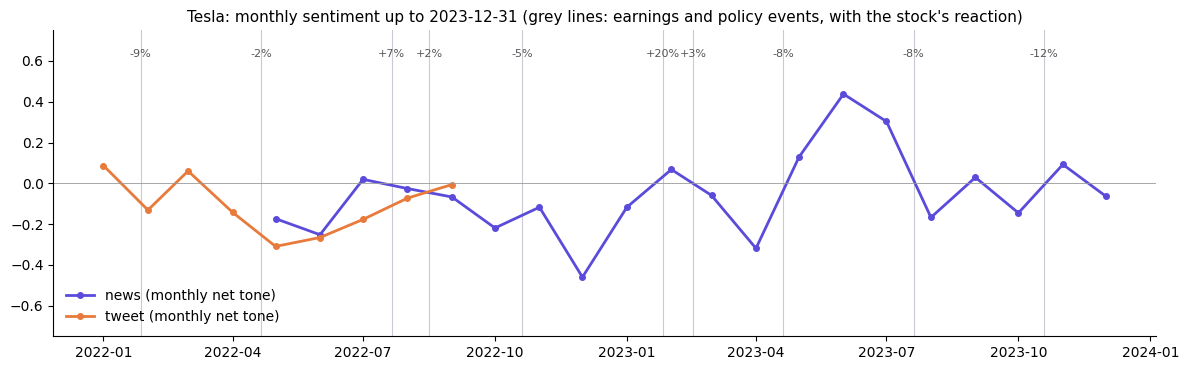

  router: 1/1 |     5s
  answers: 1/1 |    40s


date,source,time check,text
2022-05-20,news,before ✓,Looking for the Next Tesla? There Won't Be One. Tesla (NASDAQ: TSLA) has taken the market by storm in just a f…
2022-08-24,news,before ✓,What You Need to Know about Tesla’s Stock Split. The last several months for electric car maker Tesla (TSLA) h…
2022-12-22,news,before ✓,Elon Musk says he will not sell more Tesla stock for another two years. By Hyunjoo Jin and Greg Bensinger Dec …
2023-01-31,news,before ✓,Tesla’s Recovery Gains Momentum. Tesla Inc’s (NASDAQ: TSLA) shares have recently jumped as much as 75% as the …
2023-05-12,news,before ✓,US STOCKS-Wall St falls as consumer sentiment takes hit from rate hikes. The indexes rose at the opening bell …
2023-07-28,news,before ✓,2 Major Risks Investors Should Know Before Buying Tesla's Stock. Since falling to a 12-month low of $102 about…
2023-12-11,news,before ✓,"Move Over, Tesla: Wall Street Thinks This Hated Auto Stock Is a Much Better Bet in 2024. Love it or hate it, t…"
2022-10-03,news,before ✓,US STOCKS-Wall Street set to start fourth quarter on a higher note. O/R Tesla Inc TSLA.O fell 4.9% on reportin…
2022-10-03,news,before ✓,US STOCKS-Wall Street surges as final quarter begins. .N Tesla Inc TSLA.O fell 7.5% after it sold fewer-than-e…
2022-10-03,news,before ✓,"US STOCKS-S&P 500, Dow jump over 2% to kick-start fourth quarter. .N Tesla Inc TSLA.O fell 8.4% after it sold …"


{'plan': {'intent': 'trend',
  'start': Timestamp('2021-12-31 00:00:00'),
  'end': Timestamp('2023-12-31 00:00:00'),
  'periods': None,
  'event_date': None,
  'raw': '{"intent": "trend", "start": "2021-12-31", "end": "2023-12-31"}'},
 'answers': {'B6': {'steps': ['The sentiment timeline shows the monthly net tone of all documents for Tesla from May 2022 to December 2023.',
    'We need to focus on the last 2 years, which means from May 2022 to December 2023.',
    'The sentiment scores range from -0.46 (most negative) to +0.44 (most positive) during this period.',
    'The overall trend shows a mix of positive and negative sentiments, with some peaks and troughs.'],
   'answer': 'The sentiment towards Tesla has been mixed over the last 2 years, with some positive and negative periods.',
   'doc_ids': ['news_0007616',
    'news_0012377',
    'news_0018496',
    'news_0020857',
    'news_0028261',
    'news_0035730',
    'news_0049003',
    'news_0014368',
    'news_0014381',
    'news_

In [15]:
timeline_chart("Tesla", as_of="2023-12-31")
ask("How has Tesla's sentiment changed over the last 2 years?", as_of="2023-12-31", compare=False)

## Your own question --------------------------------------------------------------------------------------

Change the question and the date, then run the cell (Shift + Enter).

In [16]:
ask("Did Apple's stock outperform or underperform the Nasdaq-100 in Q2 2023?", as_of="2023-12-31", options=["outperformed", "underperformed"])

  router: 1/1 |     5s
  answers: 2/2 |    20s


date,source,time check,text
2023-04-06,news,before ✓,What's New With Apple Stock?. Apple stock (NASDAQ:AAPL) had a solid year so far rising by about 27% since earl…
2023-08-07,news,before ✓,Stocks Gain on Positive Q2 Earnings Results. Apple (AAPL) is down more than -1% to lead losers in the Dow Jone…
2023-01-10,news,before ✓,"After A Rough 2022, What Does 2023 Hold For Apple Stock?. The shares of Apple (NASDAQ:AAPL) had a tough 2022, …"
2023-08-02,news,before ✓,3 Things About Apple That Smart Investors Know. As the world's most valuable company with a market cap of over…
2023-03-31,news,before ✓,"Can the Nasdaq's Q1 Outperformance Extend to Q2?. At the end of last year, for example, I pointed out that App…"
2023-07-12,news,before ✓,Nasdaq 100 Index Shake-Up Rattles High-Flying Stocks of 2023. Those stocks dubbed the “Magnificent 7” and thei…
2023-08-15,news,before ✓,Is Apple Stock a Buy?. Apple (NASDAQ: AAPL) has long had a reputation for offering investors consistent growth…
2023-03-24,news,before ✓,1 Big Reason to Buy This Nasdaq Stock Hand Over Fist Before It Is Too Late. Apple (NASDAQ: AAPL) stock has bee…
date,source,time check,text
2023-04-06,news,before ✓,What's New With Apple Stock?. Apple stock (NASDAQ:AAPL) had a solid year so far rising by about 27% since earl…


{'plan': {'intent': 'point_in_time',
  'start': Timestamp('2023-04-01 00:00:00'),
  'end': Timestamp('2023-06-30 00:00:00'),
  'periods': None,
  'event_date': None,
  'raw': '{"intent": "point_in_time", "start": "2023-04-01", "end": "2023-06-30"}'},
 'answers': {'B6': {'steps': ['The prices tool provides monthly stock-minus-index return for Q2 2023.',
    'For 2023-04, the return was +2.4%; for 2023-05, it was -3.3%; for 2023-06, it was +3.1%.',
    'Summing these returns gives a total of +2.2% for Q2 2023.',
    'A positive stock-minus-index return indicates outperformance.'],
   'answer': 'outperformed',
   'doc_ids': ['prices_for_AAPL_vs_Nasdaq-100'],
   'explanation': "Apple's stock returned more than the Nasdaq-100 in Q2 2023."},
  'B2': {'answer': 'underperformed',
   'doc_ids': ['news_0036802'],
   'explanation': "Apple's stock was down more than -1% in Q2, while the Nasdaq-100 remained up by about 20%, indicating underperformance."}}}

In [17]:
ask("How did Nvidia's stock react to the US licence rule on top AI chips to China announced on 2022-08-31, and which other companies were hit?", as_of="2022-12-31")

  router: 1/1 |     7s
  answers: 2/2 |    24s


date,source,time check,text
2022-08-31,news,before ✓,U.S. officials order Nvidia to halt sales of top AI chips to China. By Stephen Nellis and Jane Lanhee Lee Aug …
2023-10-18,news,AFTER the as-of date,Nvidia Stock Drops on Expansion of Chip Export Restrictions to China. Nvidia (NASDAQ: NVDA) stock declined 4.7…
2022-09-01,news,before ✓,NVIDIA (NVDA) Falls 7% as US Halts Top AI Chip Sales to China. NVIDIA Corporation’s NVDA shares plunged 6.6% i…
2022-08-31,news,before ✓,"NVIDIA : U.S. Imposes New License Requirement For Future Export Of Some Chips To China, Russia. (RTTNews) - NV…"
2023-12-18,news,AFTER the as-of date,5 Things to Know About Nvidia Stock. Nvidia (NASDAQ: NVDA) has captivated Wall Street this year as its busines…
2022-09-01,news,before ✓,U.S. export ban on some advanced AI chips to hit almost all China tech majors - analysts. Chip designer Nvidia…
2022-09-01,news,before ✓,"Why Nvidia Stock Cratered on Thursday. What happened Shares of Nvidia (NASDAQ: NVDA) tumbled hard on Thursday,…"
2022-09-01,news,before ✓,"U.S. allows Nvidia to export, transfer tech to develop flagship AI chip. Adds details, background Sept 1 (Reut…"
date,source,time check,text
2022-08-31,news,before ✓,"GLOBAL MARKETS-Asia stocks stagger into September as dollar spikes. Tech stocks took a hit, dragged lower by a…"


{'plan': {'intent': 'event_impact',
  'start': Timestamp('2022-08-28 00:00:00'),
  'end': Timestamp('2022-09-09 00:00:00'),
  'periods': None,
  'event_date': Timestamp('2022-08-31 00:00:00'),
  'raw': '{"intent": "event_impact", "start": "2022-08-28", "end": "2022-09-09", "event_date": "2022-08-31", "companies": ["Nvidia"]}'},
 'answers': {'B6': {'steps': ["The US government imposed a license requirement on Nvidia's top AI chips to China on 2022-08-31.",
    "This event caused Nvidia's stock to fall significantly, with a cumulative abnormal return of -9.9% over the next 4 days.",
    'Other companies affected included AMD, which saw a -3.0% drop on the same day.',
    "The news documents provide sentiment scores and descriptions of the event's impact."],
   'answer': "Nvidia's stock fell by 9.9% in cumulative abnormal return over the next 4 days, while AMD also experienced a significant drop of 3.0% on the same day.",
   'doc_ids': ['news_0012750',
    'news_0012748',
    'news_001280